# 3 · Evaluation

Reads `features`, `predictions`, `cv_windows`, `spike_predictions` and `shap_importance` from `data/spx.db` and produces
every table and figure in the report. Nothing here fits a forecasting model.

In [1]:
import math
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy import stats
from scipy.stats import norm
from sklearn.metrics import mean_absolute_error, roc_auc_score, roc_curve, brier_score_loss, average_precision_score
from statsmodels.tsa.stattools import acf

sns.set_style('darkgrid')
pd.set_option('display.width', 160)
DB_PATH = '../data/spx.db'
SEED    = 42

In [2]:
with sqlite3.connect(DB_PATH) as con:
    df = pd.read_sql('select * from features order by date', con, index_col='date', parse_dates=['date'])
    pred = pd.read_sql('select * from predictions order by rowid', con, parse_dates=['date'])
    wins = pd.read_sql('select * from cv_windows', con, parse_dates=['date'])
    spike = pd.read_sql('select * from spike_predictions order by rowid', con, parse_dates=['date'])
    shap_importance = pd.read_sql('select * from shap_importance', con)
df['train_ok'] = df['train_ok'].astype(bool)


def runs(experiment):
    # {(model, spec): predictions indexed by date}
    sub = pred[pred['experiment'] == experiment]
    return {key: g.set_index('date')[['y_true', 'y_pred', 'state', 'block']] for key, g in sub.groupby(['model', 'spec'], sort=False)}


model_features = ['log_spread_lag1', 'log_spread_lag2', 'rv_5', 'rv_21', 'price_trend',
                  'log_volume_lag1', 'ami_lag1', 'pe_diff_lag1', 'pandemic_dummy', 'prob_state_1_lag1']
df_model = df.dropna(subset=model_features + ['y'])
main = {m: r for (m, _), r in runs('main').items()}
print({k: len(v) for k, v in main.items()})

{'XGBoost': 5695, 'LightGBM': 5695, 'Linear': 5695, 'Persistence': 5695, 'Linear (level y)': 5695}


In [3]:
def metrics(y_true, y_pred, y_bench=None):
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    mse = np.mean((y_true - y_pred) ** 2)
    out = {'RMSE': math.sqrt(mse), 'MAE': mean_absolute_error(y_true, y_pred), 'R2': 1 - mse / np.var(y_true)}
    if y_bench is not None:
        out['Skill vs Persist'] = 1 - mse / np.mean((y_true - np.asarray(y_bench, float)) ** 2)
    return out


def diebold_mariano(y_true, y1, y2, h=1, power=2, lag=None):
    # squared-error loss by default; Newey-West (Bartlett) variance, HLN correction, t(T-1) p-value.
    # Negative statistic => the first forecast has lower loss.
    y_true, y1, y2 = (np.asarray(a, float) for a in (y_true, y1, y2))
    d = np.abs(y_true - y1) ** power - np.abs(y_true - y2) ** power
    T, dbar = len(d), d.mean()
    lag = int(np.floor(T ** (1 / 3))) if lag is None else lag
    gamma = lambda k: np.sum((d[:T - k] - dbar) * (d[k:] - dbar)) / T
    S = gamma(0) + 2 * sum((1 - k / (lag + 1)) * gamma(k) for k in range(1, lag + 1))
    dm = dbar / math.sqrt(S / T)
    dm_hln = dm * math.sqrt((T + 1 - 2 * h + h * (h - 1) / T) / T)
    return dm_hln, 2 * stats.t.sf(abs(dm_hln), df=T - 1)

## 3.1 Point forecasts

In [4]:
bench = main['Persistence']['y_pred']
rows = []
for name, r in main.items():
    m = metrics(r['y_true'], r['y_pred'], bench)
    w = wins[(wins['experiment'] == 'main') & (wins['model'] == name)]
    m.update({'Avg Train RMSE': w['train_rmse'].mean(), 'Avg Val RMSE': w['val_rmse'].mean()})
    m['Overfit Gap'] = m['Avg Val RMSE'] - m['Avg Train RMSE']
    rows.append(pd.Series(m, name=name))
comparison = pd.DataFrame(rows)
print(comparison.round(6).to_string())
best_model = comparison['RMSE'].idxmin()
print("Best model by OOS RMSE:", best_model)

# sub-period metrics (the Dec-2016 level shift dominates squared errors)
split = '2016-12-01'
per = {}
for name, r in main.items():
    for lab, part in [('before 2016-12', r.loc[:split]), ('from 2016-12', r.loc[split:])]:
        per[(lab, name)] = metrics(part['y_true'], part['y_pred'], bench.loc[part.index])
display(pd.DataFrame(per).T.round(6))

ok = df_model['train_ok']
excl = {name: metrics(r.loc[ok.loc[r.index], 'y_true'], r.loc[ok.loc[r.index], 'y_pred'],
                      bench.loc[r.index][ok.loc[r.index]])
        for name, r in main.items()}
print(f"Excluding {(~ok.loc[bench.index]).sum()} flagged outlier days from the test set:")
display(pd.DataFrame(excl).T.round(6))

                      RMSE       MAE        R2  Skill vs Persist  Avg Train RMSE  Avg Val RMSE  Overfit Gap
XGBoost           0.020815  0.003630  0.278878          0.190199        0.189889      0.271424     0.081536
LightGBM          0.020865  0.003568  0.275420          0.186316        0.206850      0.266689     0.059839
Linear            0.019596  0.003293  0.360854          0.282256        0.231184      0.248880     0.017696
Persistence       0.023130  0.003698  0.109507          0.000000             NaN           NaN          NaN
Linear (level y)  0.019980  0.003622  0.335565          0.253857        0.004647      0.004625    -0.000022
Best model by OOS RMSE: Linear


,,RMSE,MAE,R2,Skill vs Persist
before 2016-12,XGBoost,0.001333,0.000643,0.657026,0.183156
from 2016-12,XGBoost,0.033067,0.008202,0.071079,0.190216
before 2016-12,LightGBM,0.001324,0.000638,0.661733,0.194367
from 2016-12,LightGBM,0.033147,0.008051,0.066582,0.186296
before 2016-12,Linear,0.001261,0.000609,0.693077,0.269018
from 2016-12,Linear,0.031130,0.007400,0.176697,0.282288
before 2016-12,Persistence,0.001475,0.000714,0.580123,0.000000
from 2016-12,Persistence,0.036746,0.008265,-0.147122,0.000000
before 2016-12,Linear (level y),0.001237,0.000610,0.704506,0.296236
from 2016-12,Linear (level y),0.031743,0.008231,0.143963,0.253752


Excluding 416 flagged outlier days from the test set:


,RMSE,MAE,R2,Skill vs Persist
XGBoost,0.012314,0.002786,0.488253,0.547062
LightGBM,0.012323,0.002722,0.487535,0.546426
Linear,0.011303,0.002574,0.568816,0.618367
Persistence,0.018297,0.003172,-0.129838,0.000000
Linear (level y),0.011769,0.002901,0.532505,0.586229


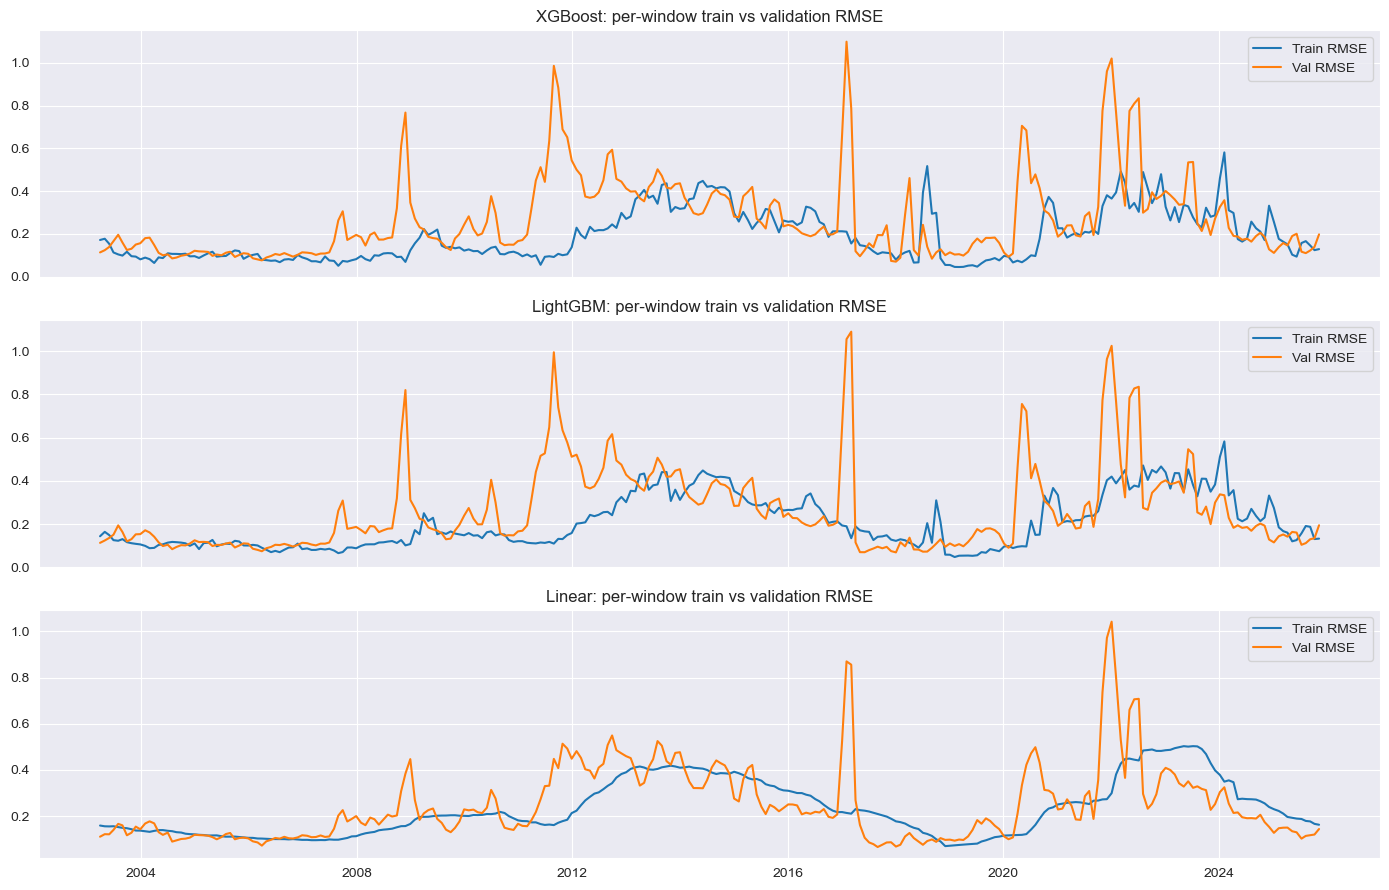

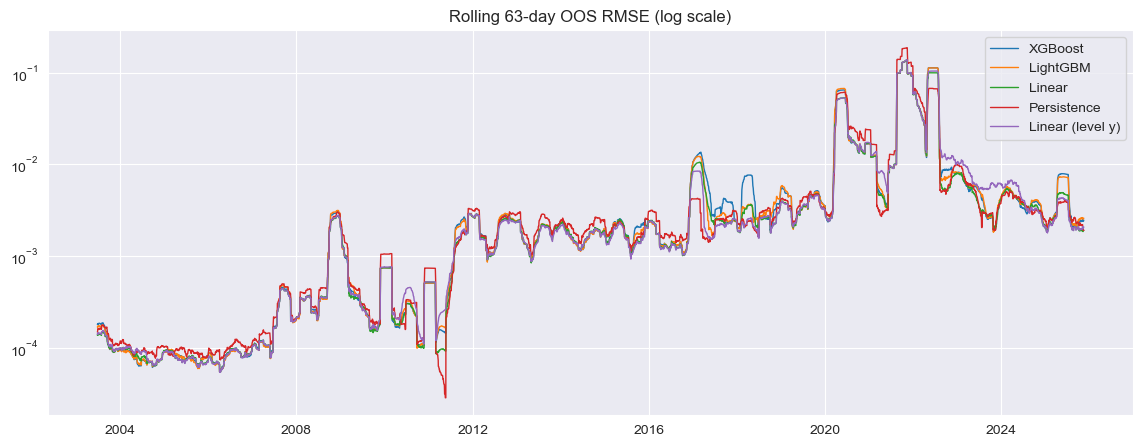

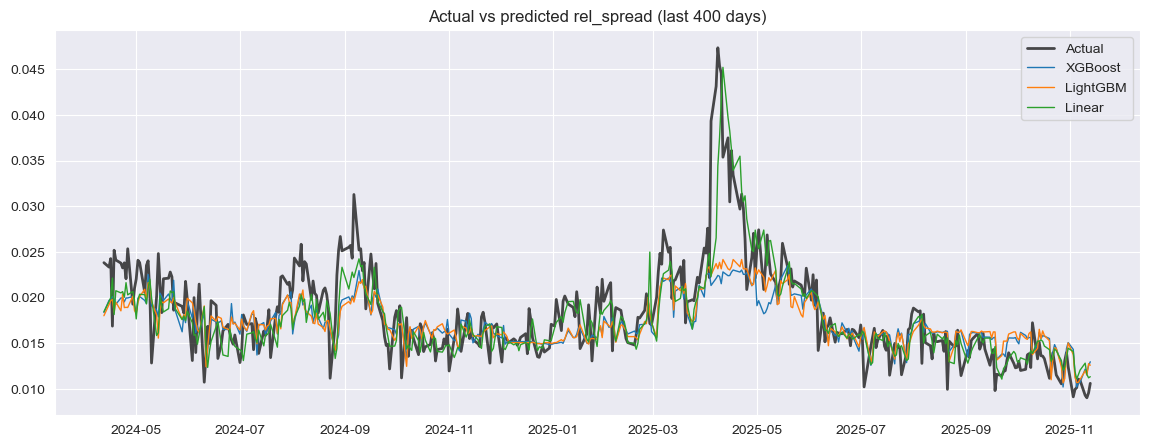

Mean |SHAP| of the last-window XGBoost model (log-spread units):
          feature  mean_abs_shap
  log_spread_lag1         0.0859
  log_spread_lag2         0.0673
            rv_21         0.0088
  log_volume_lag1         0.0086
      price_trend         0.0067
             rv_5         0.0060
     pe_diff_lag1         0.0047
prob_state_1_lag1         0.0026
         ami_lag1         0.0020
   pandemic_dummy         0.0000


In [5]:
fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
for ax, name in zip(axes, ['XGBoost', 'LightGBM', 'Linear']):
    w = wins[(wins['experiment'] == 'main') & (wins['model'] == name)].set_index('date')    # log units
    ax.plot(w.index, w['train_rmse'], label='Train RMSE'); ax.plot(w.index, w['val_rmse'], label='Val RMSE')
    ax.set_title(f'{name}: per-window train vs validation RMSE'); ax.legend()
plt.tight_layout(); plt.show()

plt.figure(figsize=(14, 5))
for name, r in main.items():
    plt.plot(((r['y_true'] - r['y_pred']) ** 2).rolling(63).mean() ** 0.5, label=name, lw=1)
plt.yscale('log'); plt.legend(); plt.title('Rolling 63-day OOS RMSE (log scale)'); plt.show()

sel = slice(-400, None)
plt.figure(figsize=(14, 5))
r0 = main['XGBoost']
plt.plot(r0.index[sel], r0['y_true'].iloc[sel], label='Actual', color='black', lw=2, alpha=0.7)
for name in ['XGBoost', 'LightGBM', 'Linear']:
    plt.plot(main[name].index[sel], main[name]['y_pred'].iloc[sel], label=name, lw=1)
plt.legend(); plt.title('Actual vs predicted rel_spread (last 400 days)'); plt.show()

print("Mean |SHAP| of the last-window XGBoost model (log-spread units):")
print(shap_importance.round(4).to_string(index=False))

## 3.2 Diebold–Mariano tests

In [6]:
y = main['Persistence']['y_true']
pairs = [('XGBoost', 'Persistence'), ('LightGBM', 'Persistence'), ('Linear', 'Persistence'),
         ('XGBoost', 'Linear'), ('LightGBM', 'Linear'), ('XGBoost', 'LightGBM'), ('Linear', 'Linear (level y)')]
dm_tab = pd.DataFrame([(a, b, *diebold_mariano(y, main[a]['y_pred'], main[b]['y_pred'])) for a, b in pairs],
                      columns=['Model A', 'Model B', 'DM (HLN)', 'p-value'])
display(dm_tab.round(4))

,Model A,Model B,DM (HLN),p-value
0,XGBoost,Persistence,-0.6560,0.5118
1,LightGBM,Persistence,-0.6439,0.5197
2,Linear,Persistence,-1.0753,0.2823
3,XGBoost,Linear,1.5624,0.1182
4,LightGBM,Linear,1.5921,0.1114
5,XGBoost,LightGBM,-0.6340,0.5261
6,Linear,Linear (level y),-1.7350,0.0828


## 3.3 Errors by regime and residual diagnostics

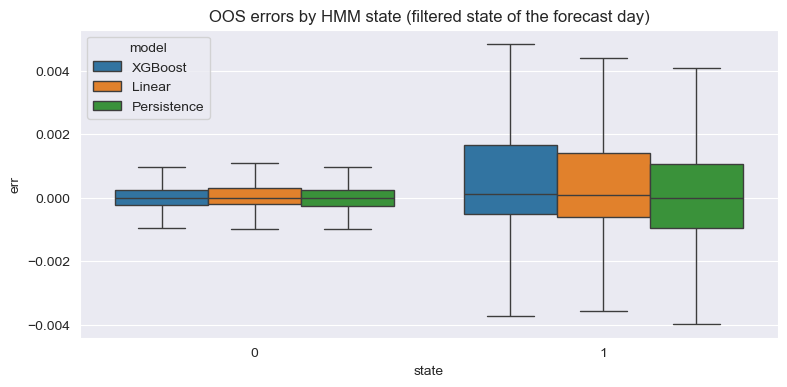

mean       std  count      RMSE
model       state                                     
Linear      0      0.000094  0.003401   2632  0.003401
            1      0.002937  0.026375   3063  0.026534
Persistence 0     -0.000922  0.017817   2632  0.017837
            1      0.000795  0.026851   3063  0.026858
XGBoost     0      0.000140  0.003656   2632  0.003658
            1      0.003581  0.027955   3063  0.028179

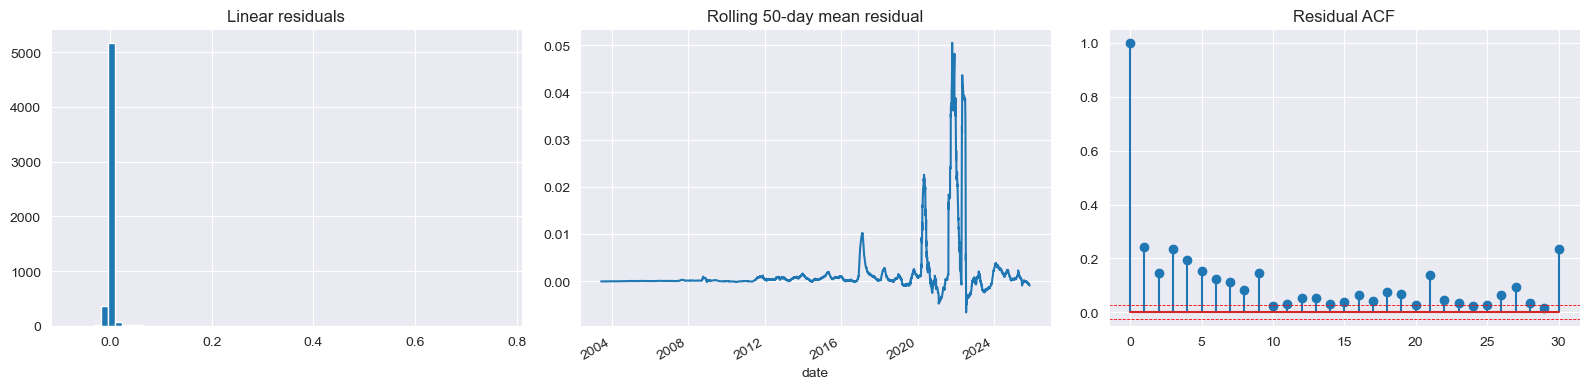

In [7]:
err_rows = []
for name in ['XGBoost', 'Linear', 'Persistence']:
    r = main[name].dropna(subset=['state'])
    err_rows.append(pd.DataFrame({'err': r['y_true'] - r['y_pred'], 'state': r['state'].astype(int), 'model': name}))
err_df = pd.concat(err_rows)

plt.figure(figsize=(9, 4))
sns.boxplot(x='state', y='err', hue='model', data=err_df, showfliers=False)
plt.title('OOS errors by HMM state (filtered state of the forecast day)'); plt.show()
display(err_df.groupby(['model', 'state'])['err'].agg(['mean', 'std', 'count',
        lambda e: np.sqrt(np.mean(e ** 2))]).rename(columns={'<lambda_0>': 'RMSE'}))

resid = main[best_model]['y_true'] - main[best_model]['y_pred']
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(resid, bins=60); axes[0].set_title(f'{best_model} residuals')
resid.rolling(50).mean().plot(ax=axes[1], title='Rolling 50-day mean residual')
acf_vals = acf(resid, nlags=30, fft=True)
axes[2].stem(acf_vals); ci = 1.96 / np.sqrt(len(resid))
axes[2].axhline(ci, c='r', ls='--', lw=0.6); axes[2].axhline(-ci, c='r', ls='--', lw=0.6)
axes[2].set_title('Residual ACF')
plt.tight_layout(); plt.show()

## 3.4 Economic value: a spread-timing rule

Trade on day t only if its forecast spread is below the median of the previous 60 days' forecasts (a causal threshold).
Cost = actual spread on the execution day / mean actual spread of its 21-day block, so the 2016 level shift does not
dominate. Below 1 means cheaper-than-average days; the oracle uses the realised spread.

In [8]:
def timing_cost(r, lookback=60):
    norm_cost = r['y_true'] / r.groupby('block')['y_true'].transform('mean')
    thr = r['y_pred'].shift(1).rolling(lookback, min_periods=20).median()
    trade = r['y_pred'] <= thr
    return norm_cost[trade].mean(), trade.mean()

econ = {name: dict(zip(['avg normalized cost', 'share of days traded'], timing_cost(r))) for name, r in main.items()}
r = main['XGBoost']
econ['Oracle (perfect foresight)'] = dict(zip(['avg normalized cost', 'share of days traded'],
                                              timing_cost(r.assign(y_pred=r['y_true']))))
econ['Trade every day'] = {'avg normalized cost': 1.0, 'share of days traded': 1.0}
econ_df = pd.DataFrame(econ).T
econ_df['saving vs every day'] = 1 - econ_df['avg normalized cost']
display(econ_df.round(4))

,avg normalized cost,share of days traded,saving vs every day
XGBoost,0.9765,0.5164,0.0235
LightGBM,0.9771,0.5008,0.0229
Linear,0.9804,0.5169,0.0196
Persistence,0.9775,0.5176,0.0225
Linear (level y),0.9748,0.5031,0.0252
Oracle (perfect foresight),0.8616,0.5175,0.1384
Trade every day,1.0000,1.0000,0.0000


## 3.5 Does the HMM improve point forecasts? Ablation

In [9]:
rows = []
for (name, _), r_wo in runs('ablation').items():
    r_w = main[name]
    stat, p = diebold_mariano(r_w['y_true'], r_w['y_pred'], r_wo['y_pred'])
    rows.append({'model': name, 'R2 with HMM': metrics(r_w['y_true'], r_w['y_pred'])['R2'],
                 'R2 without HMM': metrics(r_wo['y_true'], r_wo['y_pred'])['R2'],
                 'DM (with vs without)': stat, 'p-value': p})
display(pd.DataFrame(rows).set_index('model').round(4))

,R2 with HMM,R2 without HMM,DM (with vs without),p-value
model,,,,
XGBoost,0.2789,0.2810,0.7995,0.4240
LightGBM,0.2754,0.2739,-0.3100,0.7565
Linear,0.3609,0.3570,-0.9434,0.3455


## 3.6 HMM variants

,model,spec,R2,MAE,DM vs no HMM,p-value
0,Linear,no HMM,0.3534,0.0033,NaN,NaN
1,Linear,baseline HMM,0.3575,0.0033,-0.9680,0.3331
2,Linear,local-z HMM,0.3554,0.0033,-0.9764,0.3289
3,Linear,dynamics HMM,0.3544,0.0033,-0.6373,0.5239
4,Linear,HMM + interactions,0.3455,0.0033,0.9563,0.3390
5,LightGBM,no HMM,0.2615,0.0036,NaN,NaN
6,LightGBM,baseline HMM,0.2634,0.0036,-0.3477,0.7281
7,LightGBM,local-z HMM,0.2642,0.0036,-0.8124,0.4166
8,LightGBM,dynamics HMM,0.2608,0.0036,0.5546,0.5792
9,LightGBM,HMM + interactions,0.2604,0.0036,0.3557,0.7221


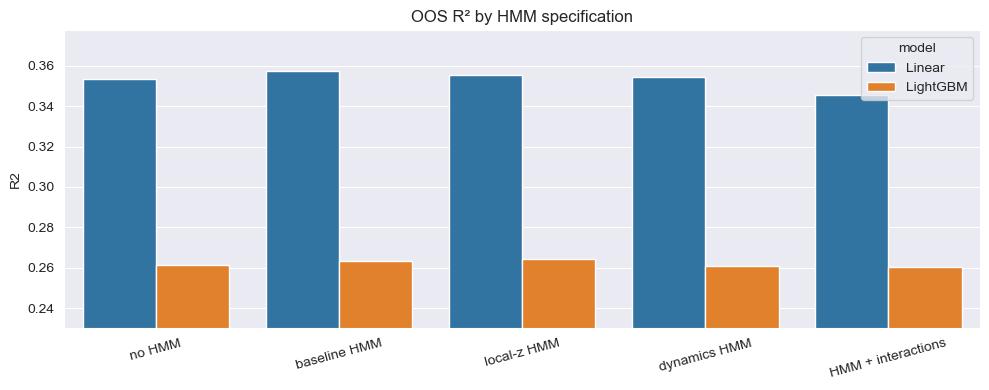

In [10]:
variants = runs('hmm_variants')
rows = []
for (name, spec), r in variants.items():
    ref = variants[(name, 'no HMM')]
    stat, p = (np.nan, np.nan) if spec == 'no HMM' else diebold_mariano(r['y_true'], r['y_pred'], ref['y_pred'])
    rows.append({'model': name, 'spec': spec, 'R2': metrics(r['y_true'], r['y_pred'])['R2'],
                 'MAE': metrics(r['y_true'], r['y_pred'])['MAE'], 'DM vs no HMM': stat, 'p-value': p})
variant_tab = pd.DataFrame(rows)
display(variant_tab.round(4))

fig, ax = plt.subplots(figsize=(10, 4))
sns.barplot(data=variant_tab, x='spec', y='R2', hue='model', ax=ax)
ax.set_ylim(variant_tab['R2'].min() - 0.03, variant_tab['R2'].max() + 0.02)
ax.set_title('OOS R² by HMM specification'); ax.set_xlabel(''); plt.xticks(rotation=15); plt.tight_layout(); plt.show()

## 3.7 Can the HMM improve forecast intervals?

90% intervals `log ŷ ± 1.645·σ_t` around the linear forecast, with σ_t from **past** OOS residuals: constant (250 days),
EWMA (λ = 0.94), regime-specific variances (baseline HMM, local-z HMM, and a non-HMM "rv_5 above its 1-year median" flag),
and EWMA scaled by the HMM regime ratio. Scored by coverage and the Gneiting–Raftery interval score (lower is better).

In [11]:
r = main['Linear'].copy()
r['e'] = np.log(r['y_true']) - np.log(r['y_pred'])              # OOS residual in log space
past_e = r['e'].shift(1)                                         # residual of day t is known only after day t
LB, ALPHA = 250, 0.10
z = norm.ppf(1 - ALPHA / 2)

def sigma_constant():
    return past_e.rolling(LB, min_periods=60).std()

def sigma_ewma(lam=0.94):
    return np.sqrt((past_e ** 2).ewm(alpha=1 - lam, min_periods=60).mean())

def sigma_regime(p):
    # p_t = P(high regime at t | info up to t-1)
    p_past, e2 = p.shift(1), past_e ** 2
    v_hi = (e2 * p_past).rolling(LB, min_periods=60).sum() / p_past.rolling(LB, min_periods=60).sum()
    v_lo = (e2 * (1 - p_past)).rolling(LB, min_periods=60).sum() / (1 - p_past).rolling(LB, min_periods=60).sum()
    return np.sqrt(p * v_hi + (1 - p) * v_lo)

p_base = df_model['prob_state_1_lag1'].reindex(r.index)
p_local = df_model['hmm_local_z_lag1'].reindex(r.index)
rv_flag = (df_model['rv_5'] > df_model['rv_5'].shift(1).rolling(252, min_periods=60).median()).astype(float).reindex(r.index)

sigmas = {
    'constant': sigma_constant(),
    'EWMA': sigma_ewma(),
    'rv_5 flag (non-HMM)': sigma_regime(rv_flag),
    'baseline HMM': sigma_regime(p_base),
    'local-z HMM': sigma_regime(p_local),
    'EWMA x local-z HMM': sigma_ewma() * sigma_regime(p_local) / sigma_constant(),
}
valid = pd.concat(sigmas, axis=1).notna().all(axis=1)
y_log, f_log = np.log(r['y_true']), np.log(r['y_pred'])

def interval_score(sig):
    lo, hi = f_log - z * sig, f_log + z * sig
    score = (hi - lo) + 2 / ALPHA * (lo - y_log).clip(lower=0) + 2 / ALPHA * (y_log - hi).clip(lower=0)
    return score[valid], ((y_log >= lo) & (y_log <= hi))[valid], (hi - lo)[valid]

rows, scores = [], {}
st = r.loc[valid, 'state']
for name, sig in sigmas.items():
    scores[name], cov, width = interval_score(sig)
    rows.append({'method': name, 'coverage': cov.mean(), 'coverage state 0': cov[st == 0].mean(),
                 'coverage state 1': cov[st == 1].mean(), 'avg width (log)': width.mean(),
                 'interval score': scores[name].mean()})
display(pd.DataFrame(rows).set_index('method').round(4))

# DM on the interval score: power=1 with a zero "truth" gives d_t = IS_a - IS_b
zero = np.zeros(valid.sum())
dm_rows = [{'method': name, 'vs': ref, **dict(zip(['DM', 'p-value'], diebold_mariano(zero, scores[name], scores[ref], power=1)))}
           for name in ['rv_5 flag (non-HMM)', 'baseline HMM', 'local-z HMM', 'EWMA x local-z HMM']
           for ref in ['constant', 'EWMA']]
display(pd.DataFrame(dm_rows).round(4))

,coverage,coverage state 0,coverage state 1,avg width (log),interval score
method,,,,,
constant,0.9013,0.9261,0.8805,0.9249,1.3661
EWMA,0.9075,0.9156,0.9008,0.9051,1.2280
rv_5 flag (non-HMM),0.9070,0.9285,0.8890,0.9369,1.3621
baseline HMM,0.9088,0.9234,0.8965,0.9344,1.3450
local-z HMM,0.9098,0.9296,0.8932,0.9518,1.3611
EWMA x local-z HMM,0.9113,0.9149,0.9083,0.9379,1.2467


,method,vs,DM,p-value
0,rv_5 flag (non-HMM),constant,-0.4582,0.6468
1,rv_5 flag (non-HMM),EWMA,4.5931,0.0000
2,baseline HMM,constant,-2.8139,0.0049
3,baseline HMM,EWMA,4.2411,0.0000
4,local-z HMM,constant,-0.6508,0.5152
5,local-z HMM,EWMA,4.5357,0.0000
6,EWMA x local-z HMM,constant,-3.9228,0.0001
7,EWMA x local-z HMM,EWMA,3.5166,0.0004


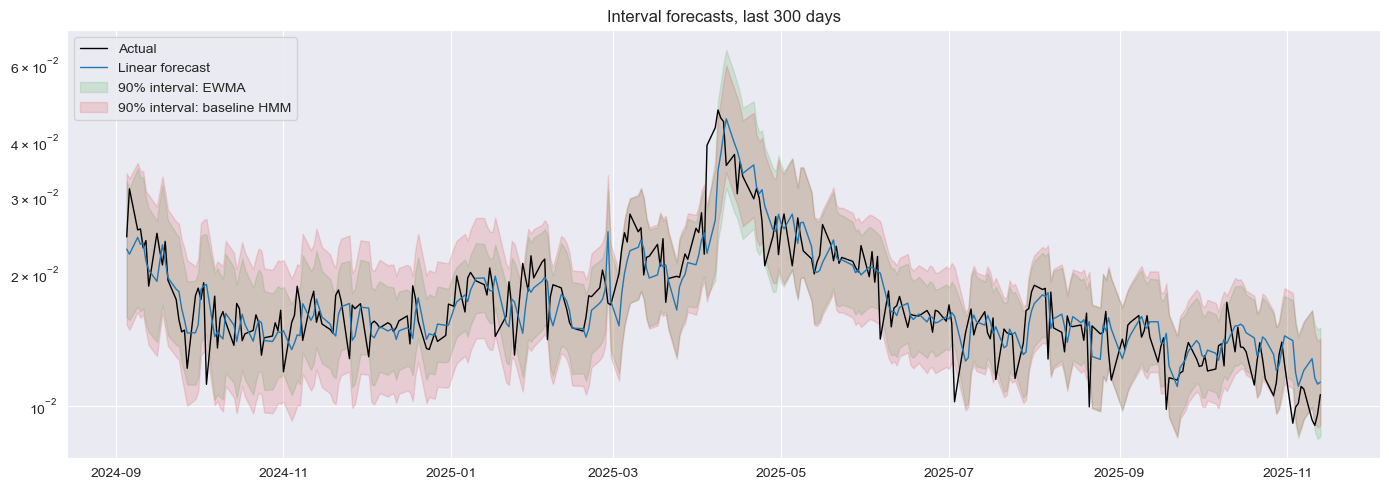

In [12]:
sel = r.index[valid][-300:]
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(sel, r.loc[sel, 'y_true'], color='black', lw=1, label='Actual')
ax.plot(sel, r.loc[sel, 'y_pred'], color='tab:blue', lw=1, label='Linear forecast')
for name, c in [('EWMA', 'tab:green'), ('baseline HMM', 'tab:red')]:
    s = sigmas[name].loc[sel]
    ax.fill_between(sel, np.exp(f_log.loc[sel] - z * s), np.exp(f_log.loc[sel] + z * s), color=c, alpha=0.15, label=f'90% interval: {name}')
ax.set_yscale('log'); ax.legend(loc='upper left'); ax.set_title('Interval forecasts, last 300 days')
plt.tight_layout(); plt.show()

## 3.8 HAR long-memory and calendar features

Squared errors on the level scale are dominated by a few spike days, so the mean absolute **log** error (≈ average percentage
error) and a DM test on squared log errors are reported too.

In [13]:
har_feats = ['har_5', 'har_22', 'har_63']
cal_feats = ['pre_holiday', 'post_holiday', 'month_end', 'month_start', 'opex', 'quad_witching',
             'dow_mon', 'dow_tue', 'dow_wed', 'dow_thu']
df_ext = df_model.dropna(subset=har_feats)
bench_ext = df_ext['spread_lag1']

har_cal = runs('har_calendar')
rows = []
for (name, spec), r in har_cal.items():
    ref = har_cal[(name, 'base')]
    m = metrics(r['y_true'], r['y_pred'], bench_ext.loc[r.index])
    row = {'model': name, 'spec': spec, 'R2': m['R2'], 'Skill vs Persist': m['Skill vs Persist'],
           'MAE (log)': np.mean(np.abs(np.log(r['y_true']) - np.log(r['y_pred'])))}
    if spec != 'base':
        row['DM level p'] = diebold_mariano(r['y_true'], r['y_pred'], ref['y_pred'])[1]
        row['DM log'], row['DM log p'] = diebold_mariano(np.log(r['y_true']), np.log(r['y_pred']), np.log(ref['y_pred']))
    rows.append(row)
r = har_cal[('Linear', 'base')]
rows.append({'model': 'Persistence', 'spec': '-', 'R2': metrics(r['y_true'], bench_ext.loc[r.index])['R2'],
             'Skill vs Persist': 0.0, 'MAE (log)': np.mean(np.abs(np.log(r['y_true']) - np.log(bench_ext.loc[r.index])))})
display(pd.DataFrame(rows).round(4))

# which calendar effects exist at all? in-sample OLS of the daily log spread change on calendar dummies (HAC t-stats)
dly = np.log(df_ext['y']) - df_ext['log_spread_lag1']
ols = sm.OLS(dly, sm.add_constant(df_ext[cal_feats])).fit(cov_type='HAC', cov_kwds={'maxlags': 10})
print("Calendar effects on the daily change of log spread (in-sample, HAC):")
print(pd.DataFrame({'coef': ols.params, 't': ols.tvalues}).drop('const').round(3).to_string())

,model,spec,R2,Skill vs Persist,MAE (log),DM level p,DM log,DM log p
0,Linear,base,0.3609,0.2823,0.2100,NaN,NaN,NaN
1,Linear,+HAR,0.3595,0.2808,0.1933,0.9348,-3.6861,0.0002
2,Linear,+calendar,0.3605,0.2819,0.2094,0.8293,-0.4589,0.6463
3,Linear,+HAR+calendar,0.3594,0.2806,0.1930,0.9292,-3.5382,0.0004
4,LightGBM,base,0.2754,0.1863,0.2293,NaN,NaN,NaN
5,LightGBM,+HAR,0.2918,0.2047,0.2214,0.0372,-2.4186,0.0156
6,LightGBM,+calendar,0.2731,0.1837,0.2277,0.3854,-1.8283,0.0676
7,LightGBM,+HAR+calendar,0.2875,0.1999,0.2202,0.1034,-2.4595,0.0139
8,Persistence,-,0.1095,0.0000,0.2205,NaN,NaN,NaN


Calendar effects on the daily change of log spread (in-sample, HAC):
                coef      t
pre_holiday    0.060  2.365
post_holiday   0.002  0.050
month_end      0.010  0.387
month_start   -0.081 -3.330
opex          -0.062 -2.274
quad_witching  0.069  1.757
dow_mon        0.004  0.172
dow_tue        0.030  1.724
dow_wed        0.023  1.321
dow_thu        0.032  1.847


## 3.9 Spike forecasting

Metrics: ROC-AUC, average precision, Brier score, and precision among the 10% of days with the highest predicted risk.
AUC differences use a 21-day block bootstrap. The vendor level shifts (2011, 2016) also show up as runs of "spikes" until
the rolling threshold catches up.

In [14]:
clf_res = {spec: g.set_index('date')[['y', 'p', 'state']] for spec, g in spike.groupby('spec', sort=False)}
idx = clf_res['logit, no HMM'].index
for col in ['spike_lag1', 'dist_to_thr']:
    clf_res[f'naive: {col}'] = clf_res['logit, no HMM'][['y', 'state']].assign(p=df.loc[idx, col])

def clf_metrics(r, is_prob=True):
    top = r.nlargest(int(len(r) * 0.1), 'p')
    return {'AUC': roc_auc_score(r['y'], r['p']), 'Avg precision': average_precision_score(r['y'], r['p']),
            'Brier': brier_score_loss(r['y'], r['p']) if is_prob else np.nan,
            'Precision@top10%': top['y'].mean(), 'Base rate': r['y'].mean()}

clf_tab = pd.DataFrame({lab: clf_metrics(r, is_prob=not lab.startswith('naive: dist')) for lab, r in clf_res.items()}).T
display(clf_tab.round(4))

rng = np.random.default_rng(SEED)
def auc_diff_ci(a, b, B=1000, block=21):
    n = len(a); diffs = []
    for _ in range(B):
        ix = np.concatenate([np.arange(s, s + block) for s in rng.integers(0, n - block, n // block)])
        y = a['y'].values[ix]
        if y.min() != y.max():
            diffs.append(roc_auc_score(y, a['p'].values[ix]) - roc_auc_score(y, b['p'].values[ix]))
    lo, hi = np.percentile(diffs, [2.5, 97.5])
    return roc_auc_score(a['y'], a['p']) - roc_auc_score(b['y'], b['p']), lo, hi

pairs = [('logit, no HMM', 'naive: dist_to_thr'), ('logit, +HMM+HAR+cal', 'naive: dist_to_thr'),
         ('logit, +HMM', 'logit, no HMM'), ('LGB, +HMM', 'LGB, no HMM'),
         ('logit, +HMM+HAR+cal', 'logit, +HMM'), ('LGB, +HMM+HAR+cal', 'logit, +HMM+HAR+cal')]
display(pd.DataFrame([(a, b, *auc_diff_ci(clf_res[a], clf_res[b])) for a, b in pairs],
                     columns=['A', 'B', 'AUC diff', '95% CI low', '95% CI high']).round(4))

,AUC,Avg precision,Brier,Precision@top10%,Base rate
"logit, no HMM",0.8263,0.5475,0.0962,0.6069,0.1519
"logit, +HMM",0.8233,0.5447,0.0966,0.6146,0.1519
"logit, +HMM+HAR+cal",0.8412,0.5644,0.0952,0.6185,0.1519
"LGB, no HMM",0.8127,0.5045,0.1020,0.5819,0.1519
"LGB, +HMM",0.8107,0.5011,0.1023,0.5703,0.1519
"LGB, +HMM+HAR+cal",0.8137,0.4936,0.1030,0.5684,0.1519
naive: spike_lag1,0.7243,0.3544,0.1421,0.5183,0.1519
naive: dist_to_thr,0.8330,0.5321,NaN,0.6224,0.1519


,A,B,AUC diff,95% CI low,95% CI high
0,"logit, no HMM",naive: dist_to_thr,-0.0067,-0.0225,0.0096
1,"logit, +HMM+HAR+cal",naive: dist_to_thr,0.0083,-0.0107,0.0269
2,"logit, +HMM","logit, no HMM",-0.0030,-0.0071,0.0008
3,"LGB, +HMM","LGB, no HMM",-0.0020,-0.0074,0.0032
4,"logit, +HMM+HAR+cal","logit, +HMM",0.0179,0.0047,0.0311
5,"LGB, +HMM+HAR+cal","logit, +HMM+HAR+cal",-0.0275,-0.0451,-0.0115


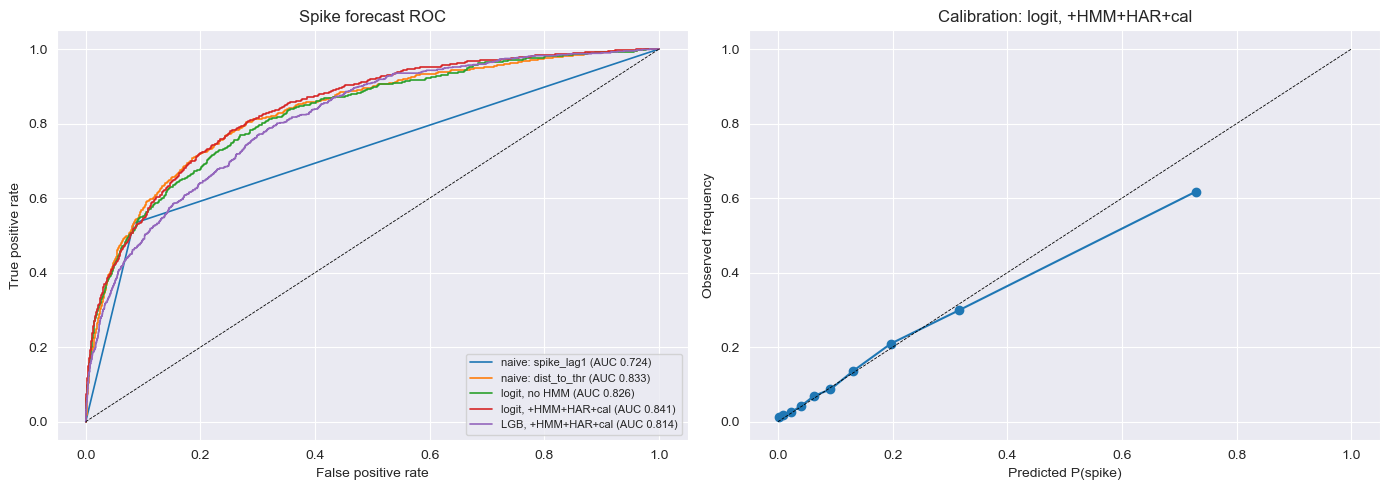

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for lab in ['naive: spike_lag1', 'naive: dist_to_thr', 'logit, no HMM', 'logit, +HMM+HAR+cal', 'LGB, +HMM+HAR+cal']:
    r = clf_res[lab]
    fpr, tpr, _ = roc_curve(r['y'], r['p'])
    axes[0].plot(fpr, tpr, lw=1.2, label=f"{lab} (AUC {roc_auc_score(r['y'], r['p']):.3f})")
axes[0].plot([0, 1], [0, 1], 'k--', lw=0.6); axes[0].set_xlabel('False positive rate'); axes[0].set_ylabel('True positive rate')
axes[0].set_title('Spike forecast ROC'); axes[0].legend(fontsize=8)

best_clf = clf_tab.drop(index=[i for i in clf_tab.index if i.startswith('naive')])['AUC'].idxmax()
r = clf_res[best_clf].copy()
r['bin'] = pd.qcut(r['p'], 10, labels=False, duplicates='drop')
cal = r.groupby('bin').agg(pred=('p', 'mean'), obs=('y', 'mean'))
axes[1].plot(cal['pred'], cal['obs'], marker='o'); axes[1].plot([0, 1], [0, 1], 'k--', lw=0.6)
axes[1].set_xlabel('Predicted P(spike)'); axes[1].set_ylabel('Observed frequency'); axes[1].set_title(f'Calibration: {best_clf}')
plt.tight_layout(); plt.show()

## Summary

* **Point forecasts.** A linear regression on `log(spread)` is the most accurate model (OOS R² ≈ 0.36, MSE about 28% below
  persistence); gradient boosting overfits more and does not beat it. HAR long-memory features significantly reduce
  typical-day errors (mean absolute log error ≈ 0.21 → 0.19); calendar effects exist in-sample but do not help forecasts.
* **HMM.** The rolling HMM identifies persistent regimes, and forecast errors are several times larger in the high-spread
  regime, so the regime is a useful risk flag. As a predictor it adds no out-of-sample value for point forecasts, spike
  classification, or (relative to an EWMA of past residuals) interval forecasts.
* **Spikes.** Predictable (AUC ≈ 0.84), but almost entirely from how close yesterday's spread was to the threshold.
* **Data.** Vendor-filled holiday rows and two level shifts in the index quote (June 2011, December 2016) shape every result.